# Generating Company Names with a Character-Level Transformer

**Author:** Mauro Reverberi

**Program:** MSc AI, Udacity Institute of AI & Technology / Woolf

**Project:** Capstone Project 5, Generative AI Applications

**Dataset:** Companies House, Free Company Data Product, snapshot of 2026-10-01:
https://download.companieshouse.gov.uk/en_output.html

TBD

**Research question:** Can a small character-level Transformer generate plausible and varied company names without mostly copying the names it was trained on or the names of companies that already exist?

I picked this task because it connects to my earlier capstone projects, which all work with company data for compliance checks. Project 1 built a dataset of Swiss legal entities from the GLEIF register, and Projects 2 to 4 analyzed company registrations, a bankruptcy score and negative news about companies. A later capstone project will build a due diligence agent that matches company names against registers and lists. Generated names could serve as extra test inputs for this step, names that look real but should not match anything. They are not a matching benchmark, which would need pairs of names that are known to be the same or different companies.

## Problem definition and dataset

**Task type:** TBD

**Dataset:** Companies House publishes a free monthly snapshot of all live companies on the UK register. I downloaded the snapshot of 2026-10-01 with 5,704,711 companies. Companies House imposes no rules on how the information on the public register is used, but rights of third parties in the data remain. The names are real register entries, nothing is synthetic, and I did not use this source in my earlier capstone projects.

`prepare_dataset.py` keeps the private limited companies whose names use only capital letters, digits and common punctuation, have at most 60 characters and end with LTD, LTD. or LIMITED. From the 5,259,281 different names it draws a random sample of 100,000 with seed 42. Very similar names like ACME HOLDINGS LTD and ACME HOLDINGS (UK) LIMITED form one group, so they cannot end up in training and test. The script splits the groups about 80/10/10 into train, validation and test. Names with the same first word and a different second word can still land in different splits.

The script also computes a key for every live company. The key follows the "same as" rules that Companies House uses to refuse a new name (Schedule 3 of the Names and Trading Disclosures Regulations 2015), so HANDS UK LTD and HAND'S LIMITED get the same key, and so do ACME 2 LTD and ACME TWO LTD. I wrote the key myself, and it is not the official test. It does not cover the exceptions or the separate "too like" test, which Companies House decides case by case. So a key match is only a possible collision with a real company, and a name without a match can still be too close to one. The 64-bit hashes of the keys are in `register_key_hashes.npy`, so a name can be checked against the register without keeping 5.7 million names in the repository.

## Setup

I use CUDA if it is available, otherwise the CPU. Seed 42 is the main seed of the notebook, the same as in `prepare_dataset.py`. I do not use the Apple GPU (MPS), because two runs with the same seed gave slightly different results there.

In [1]:
import math
import os
import random
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from torch.utils.data import DataLoader, TensorDataset

from constants import DATA_FILE, NAME_ENDINGS, REGISTER_FILE, SEED
from model import NameGPT
from ngram import CharNgram
from prepare_dataset import key_hash, same_as_key
from tokenizer import END, PAD, CharTokenizer

In [2]:
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
# deterministic algorithms where possible, CUDA needs the cuBLAS setting, warn_only avoids errors
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
torch.use_deterministic_algorithms(True, warn_only=True)

In [3]:
# a name has at most 60 characters, plus the end marker in front
CONTEXT_SIZE = 61
BATCH_SIZE = 128
# larger batches for the evaluation, they need no gradients
EVAL_BATCH_SIZE = 512
EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01
# sampling settings for the generation
TEMPERATURES = [0.5, 0.8, 1.0, 1.2]
NAMES_PER_TEMPERATURE = 2000
# weights and loss history of the run that the text describes, written once
REFERENCE_DIR = Path("reference_run")
# a later training run goes here, a further run replaces its files
NEW_RUN_DIR = Path("new_run")
# True trains a model, False only loads a saved run
TRAIN_MODEL = False
# True analyses the reference run, False the run in NEW_RUN_DIR
ANALYSE_REFERENCE_RUN = True

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")

device: cpu


In [5]:
def set_seed(seed):
    """Set the seed of random, NumPy and PyTorch, so a run can be repeated."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)

## Load the dataset

I load the prepared sample, one row per company name, and the hashes of the register keys. I check the structure before I touch anything.

In [6]:
names = pd.read_csv(DATA_FILE, keep_default_na=False)
names["split"] = pd.Categorical(names["split"], ["train", "validation", "test"])
register_keys = np.load(REGISTER_FILE)
print(f"Rows: {names.shape[0]:,}, columns: {names.shape[1]}")
print(f"Register keys: {len(register_keys):,}")

Rows: 100,000, columns: 3
Register keys: 5,673,818


In [7]:
names.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 3 columns):
 #   Column  Non-Null Count   Dtype   
---  ------  --------------   -----   
 0   name    100000 non-null  str     
 1   group   100000 non-null  int64   
 2   split   100000 non-null  category
dtypes: category(1), int64(1), str(1)
memory usage: 1.6 MB


In [8]:
names.head()

,name,group,split
0,CF TROY UB INSURED LIMITED,17178,train
1,AHQENZA LIMITED,3582,train
2,INNSIGHT ADVISORS LTD,42646,train
3,HANN ELECTRICAL LTD,37927,train
4,GG-030-615 LIMITED,34636,train


The file has 100,000 rows and three columns, the name, the number of its name group and the split. No value is missing. All names are in capital letters, because the register stores almost all names this way and `prepare_dataset.py` removes the few others. Next to ordinary names like HANN ELECTRICAL LTD the first rows already show GG-030-615 LIMITED, which looks more like a code than a name.

The register file has 5,673,818 different keys for the 5,704,711 live companies of the snapshot, 30,893 fewer keys than company records. Some names may be allowed within a group of companies or with consent, and my key may also merge names that the official rules keep apart. I did not count the records per key.

## Data checks

Before I train anything I want to see what the names look like, how long they are, which characters and words appear and whether the split keeps related names together.

In [9]:
names.groupby("split", observed=True).sample(4, random_state=SEED)

,name,group,split
3974,MJ ROCKET LTD,57294,train
49261,IMPACT FLOORING SPECIALISTS LIMITED,42053,train
14637,EVD GUILDFORD LTD,29750,train
4623,SMITH HOUSING MORPETH LTD,79477,train
91140,RHODES&CO LIMITED,72462,validation
31094,POWERFUL POSITIONS LIMITED,67967,validation
98148,CITY ESSENTIALS LTD,18399,validation
36470,LINK MERCHANT SERVICES LTD,51009,validation
82742,PHONEGEEKS CITY LTD,66609,test
7625,SHULTON (GREAT BRITAIN) LIMITED,77952,test


In [10]:
names["length"] = names["name"].str.len()
names["ending"] = names["name"].str.split().str[-1]
names["words"] = names["name"].str.split().str.len()
print(names.groupby("split", observed=True)["name"].count())
print()
print("Endings:")
print(names["ending"].value_counts())
print()
print(names[["length", "words"]].describe().round(2))

split
train         80142
validation     9835
test          10023
Name: name, dtype: int64

Endings:
ending
LTD        51620
LIMITED    47376
LTD.        1004
Name: count, dtype: int64

          length      words
count  100000.00  100000.00
mean       22.97       3.49
std         7.81       1.03
min         6.00       2.00
25%        17.00       3.00
50%        22.00       3.00
75%        28.00       4.00
max        60.00      13.00


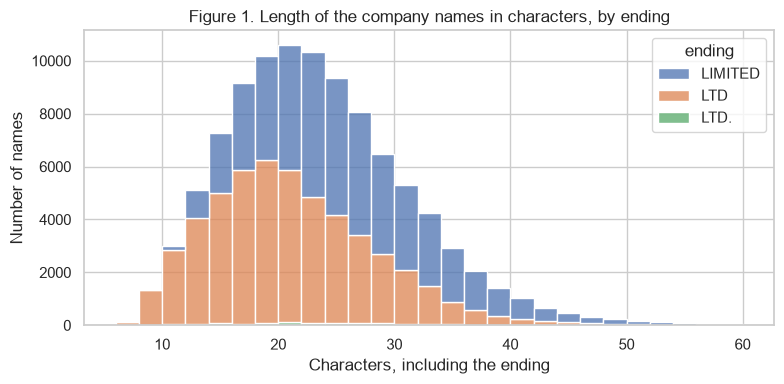

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=names, x="length", hue="ending", multiple="stack", binwidth=2, ax=ax)
ax.set_title("Figure 1. Length of the company names in characters, by ending")
ax.set_xlabel("Characters, including the ending")
ax.set_ylabel("Number of names")
plt.tight_layout()
plt.show()

**Interpretation:** 51,620 names end with LTD, 47,376 with LIMITED and only 1,004 with LTD. (with a full stop). The median name has 22 characters and 3 words. The maximum length is 60 characters, my limit, and the maximum word count is 13. Figure 1 shows that most names are between 10 and 40 characters long. The LTD names peak at about 20 characters and the LIMITED names a few characters later, which fits the four extra letters of LIMITED.

In [12]:
characters = Counter("".join(names["name"]))
print(f"{len(characters)} different characters")
print("".join(sorted(characters)))
print()
print("Rarest characters:")
print(sorted(characters.items(), key=lambda item: item[1])[:8])

48 different characters
 !&'()+,-./0123456789@ABCDEFGHIJKLMNOPQRSTUVWXYZ

Rarest characters:
[('!', 15), ('@', 33), ('+', 45), ('/', 93), (',', 373), ('9', 628), ('6', 676), ('7', 680)]


In [13]:
def name_words(name):
    """Return the words of a name without its ending LTD, LTD. or LIMITED."""
    words = name.split()
    return words[:-1] if words and words[-1] in NAME_ENDINGS else words


train_names = names.loc[names["split"] == "train", "name"].tolist()
word_counts = Counter(word for name in train_names for word in set(name_words(name)))
top_words = pd.DataFrame(word_counts.most_common(15), columns=["word", "names"])
top_words["share"] = (top_words["names"] / len(train_names)).round(4)
top_words

,word,names,share
0,SERVICES,3850,0.0480
1,&,3604,0.0450
2,PROPERTY,2113,0.0264
3,AND,1942,0.0242
4,GROUP,1873,0.0234
5,SOLUTIONS,1810,0.0226
6,MANAGEMENT,1806,0.0225
7,THE,1785,0.0223
8,PROPERTIES,1746,0.0218
9,HOLDINGS,1712,0.0214


**Interpretation:** After the preparation 48 different characters remain, the space, 26 capital letters, 10 digits and 11 punctuation marks. The rarest ones are `!` (15 times), `@` (33) and `+` (45). The most frequent words (without the ending) are generic business words. SERVICES appears in 4.8% of the training names, `&` in 4.5%, PROPERTY in 2.6%, followed by AND, GROUP, SOLUTIONS, MANAGEMENT, THE, PROPERTIES and HOLDINGS with about 2% each. No single word dominates.

In [14]:
# the preparation keeps every name group in one split, I check this first
splits_per_group = names.groupby("group")["split"].nunique()
spread = (splits_per_group > 1).sum()
print(f"Groups: {len(splits_per_group):,}, spread over more than one split: {spread}")
group_sizes = names["group"].value_counts()
shared = group_sizes[group_sizes > 1]
print(f"Groups with more than one name: {len(shared):,} ({shared.sum():,} names)")
largest = group_sizes.index[0]
names[names["group"] == largest].head(8)

Groups: 95,078, spread over more than one split: 0
Groups with more than one name: 1,901 (6,823 names)


,name,group,split,length,ending,words
3339,A&Z FARM (LINCOLN) LIMITED,1380,train,26,LIMITED,4
4001,A & L MOTS LTD,1380,train,14,LTD,5
4604,A & H JOINERY ASSOCIATES LTD,1380,train,28,LTD,6
4702,A&M LUXURY LIMITED,1380,train,18,LIMITED,3
5553,A & M MANAGEMENT LTD,1380,train,20,LTD,5
6280,A&S UK CONSULTING LIMITED,1380,train,25,LIMITED,4
6671,A&A BEAUTY CLINIC LTD,1380,train,21,LTD,4
9565,A&J DEVELOPMENTS (NW) LIMITED,1380,train,29,LIMITED,4


**Interpretation:** None of the 95,078 groups is spread over two splits. 1,901 groups have more than one name, 6,823 names in total, and all other names form a group of their own. The largest group shows a weakness of my rule. After the normalization, A&Z FARM (LINCOLN) LIMITED and A & L MOTS LTD both start with the words A AND, although they are clearly different companies. I did not count how many groups join different companies this way.

## Preprocessing for the model

The names are split into single characters. The `CharTokenizer` in `tokenizer.py` maps every character to an id and adds two special tokens. The padding token has the id 0, and the end marker `\n` (a line break, which never appears in a name) gets the id 1 and stands at the start and at the end of every name.

Every name becomes one row of `CONTEXT_SIZE` (61) ids. The input is the marker plus the name, the target the name plus the marker, and the rest of the row is padding.

In [15]:
tokenizer = CharTokenizer.train_from_names(train_names)
# the vocabulary comes from the training names only, so I check that no other split needs more
unseen = set("".join(names["name"])) - set("".join(train_names))
print(f"Characters in validation or test that are not in training: {len(unseen)}")
PAD_ID = tokenizer.token_id_for_char[PAD]
END_ID = tokenizer.token_id_for_char[END]
print(f"Vocabulary size: {tokenizer.vocabulary_size()}")
print(tokenizer.encode("ACME LTD"))
print(tokenizer.decode(tokenizer.encode("ACME LTD")))

Characters in validation or test that are not in training: 0
Vocabulary size: 50
[24, 26, 36, 28, 2, 35, 43, 27]
ACME LTD


In [16]:
def encode_names(name_list):
    """Return the input and target tensors, one row per name, padded with PAD_ID."""
    inputs = torch.full((len(name_list), CONTEXT_SIZE), PAD_ID, dtype=torch.long)
    targets = torch.full((len(name_list), CONTEXT_SIZE), PAD_ID, dtype=torch.long)
    for row, name in enumerate(name_list):
        ids = [END_ID] + tokenizer.encode(name) + [END_ID]
        inputs[row, :len(ids) - 1] = torch.tensor(ids[:-1])
        targets[row, :len(ids) - 1] = torch.tensor(ids[1:])
    return inputs, targets


data = {split: encode_names(names.loc[names["split"] == split, "name"].tolist())
        for split in ["train", "validation", "test"]}
for split, (inputs, targets) in data.items():
    to_predict = (targets != PAD_ID).sum().item()
    print(f"{split}: inputs {tuple(inputs.shape)}, characters to predict {to_predict:,}")
print()
print("First training name:", repr(train_names[0]))
print("input: ", data["train"][0][0, :12].tolist())
print("target:", data["train"][1][0, :12].tolist())

train: inputs (80142, 61), characters to predict 1,921,021
validation: inputs (9835, 61), characters to predict 235,552
test: inputs (10023, 61), characters to predict 240,086

First training name: 'CF TROY UB INSURED LIMITED'
input:  [1, 26, 29, 2, 43, 41, 38, 48, 2, 44, 25, 2]
target: [26, 29, 2, 43, 41, 38, 48, 2, 44, 25, 2, 32]


**Interpretation:** The vocabulary comes from the training names and has 50 tokens, the 48 characters plus padding and end marker. Validation and test contain no character that is missing in training. ACME LTD becomes eight ids and back again. The training split has 1,921,021 characters to predict (the end markers included), validation 235,552 and test 240,086. The first training name shows the shift by one place. The input starts with 1, the end marker, and the target with 26, the id of C.

## Reference model without deep learning

As a first model I build a simple reference, a character n-gram model from `ngram.py`. It counts which character follows the last n - 1 characters in the training names and turns the counts into probabilities. Add-k smoothing gives every character a small probability even after a context it never saw. I try the orders 2 to 5 and three values of k and keep the combination with the lowest validation loss, the cross-entropy per character in nats. The reference shows how far a model that only uses local contexts gets.

In [17]:
validation_names = names.loc[names["split"] == "validation", "name"].tolist()
test_names = names.loc[names["split"] == "test", "name"].tolist()

rows = []
for order in [2, 3, 4, 5]:
    for k in [0.01, 0.1, 1.0]:
        model_ngram = CharNgram(tokenizer, order, k).fit(train_names)
        rows.append({"order": order, "k": k, "validation_loss": model_ngram.loss(validation_names)})
ngram_results = pd.DataFrame(rows)
best_ngram = ngram_results.loc[ngram_results["validation_loss"].idxmin()]
ngram = CharNgram(tokenizer, int(best_ngram["order"]), best_ngram["k"]).fit(train_names)
print(f"Best reference: order {int(best_ngram['order'])}, k = {best_ngram['k']}, "
      f"validation loss {best_ngram['validation_loss']:.4f} nats per character")
ngram_results.pivot(index="order", columns="k", values="validation_loss").round(4)

Best reference: order 5, k = 0.1, validation loss 1.3680 nats per character


k,0.01,0.10,1.00
order,,,
2,2.3007,2.3004,2.3005
3,1.7570,1.7515,1.7573
4,1.4522,1.4283,1.4832
5,1.4046,1.3680,1.5350


**Interpretation:** The best loss falls with every step of the order, from 2.3004 nats per character for the bigram model to 1.3680 for the 5-gram model with k = 0.1. At order 5 a large k hurts (1.5350 with k = 1), probably because many contexts of four characters appear only a few times, and a large k then puts too much probability on characters that never followed them. I did not try orders above 5, where the contexts would be even rarer.

## Model

The architecture is the decoder-only Transformer from the course, built from my own PyTorch classes in `model.py` (`AttentionHead`, `MultiHeadAttention`, `FeedForward`, `Block` and `NameGPT`). Nothing is pretrained.

A token embedding and a learned position embedding turn every character into a vector of 256 numbers. Four blocks follow, each with causal self-attention over eight heads and a feed-forward part (256 to 1,024 to 256 with GELU), each part with a layer norm in front and a residual connection around it. A final layer norm and a linear layer give one logit per token. The causal mask lets a position see only itself and the earlier characters.

**Why this design:** company names are short, 61 positions are enough, but their structure reaches over more than a few characters, for example the ending or a closing bracket. Self-attention can use the whole name so far, the n-gram reference only the last four characters. I train from scratch instead of fine-tuning a pretrained model like GPT-2, because a pretrained model has read web text with real company names, so a copied name could also come from its pretraining.

In [18]:
config = {
    "vocabulary_size": tokenizer.vocabulary_size(),
    "context_size": CONTEXT_SIZE,
    "embedding_dim": 256,
    "heads_num": 8,
    "layers_num": 4,
    "dropout_rate": 0.1,
    "use_bias": False,
}
config["head_size"] = config["embedding_dim"] // config["heads_num"]

In [19]:
set_seed(SEED)
model = NameGPT(config).to(device)
total = sum(p.numel() for p in model.parameters())
print(f"Parameters: {total:,}")
# a quick check with an untrained model, the loss should be close to log(vocabulary size)
inputs, targets = data["validation"][0][:4].to(device), data["validation"][1][:4].to(device)
logits = model(inputs)
print(f"Logits shape: {tuple(logits.shape)}")
untrained_loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1),
                                 ignore_index=PAD_ID)
expected_loss = math.log(config["vocabulary_size"])
print(f"Loss before training: {untrained_loss.item():.4f}, "
      f"log(vocabulary size) = {expected_loss:.4f}")
print(model)

Parameters: 3,197,696
Logits shape: (4, 61, 50)
Loss before training: 4.0161, log(vocabulary size) = 3.9120
NameGPT(
  (token_embedding_layer): Embedding(50, 256)
  (positional_embedding_layer): Embedding(61, 256)
  (layers): Sequential(
    (0): Block(
      (multi_head): MultiHeadAttention(
        (heads): ModuleList(
          (0-7): 8 x AttentionHead(
            (Q_weights): Linear(in_features=256, out_features=32, bias=False)
            (K_weights): Linear(in_features=256, out_features=32, bias=False)
            (V_weights): Linear(in_features=256, out_features=32, bias=False)
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
        (linear): Linear(in_features=256, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (layer_norm_1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
      (feed_forward): FeedForward(
        (linear_layers): Sequential(
          (0): Linear(in_features=256, out_fe

**Interpretation:** The model has 3,197,696 parameters. Before training its loss on four validation names is 4.0161, close to log(50) = 3.9120, the loss of a model that gives all 50 tokens the same probability. So the forward pass and the loss work as expected with random weights. The printout shows the four identical blocks, each with eight heads of size 32.

## Training

The loss is the cross-entropy between the predicted distribution of the next character and the real next character, averaged over all characters and end markers, with the padding ignored. It measures how surprised the model is by the real names. The optimizer is AdamW with a learning rate of 1e-3, weight decay 0.01 and batches of 128 names. The learning rate and the weight decay are the default values of AdamW in PyTorch, and I did not search for better ones. Dropout 0.1 sits in the attention weights, after the attention output and after the feed-forward part.

I train for 20 epochs with a seeded batch order and keep the weights of the epoch with the lowest validation loss. The first run saves them in `reference_run`, a later run in `new_run`, and by default the analysis loads the reference run.

In [20]:
def run_epoch(model, inputs, targets, optimizer=None, generator=None):
    """Train one epoch with an optimizer or evaluate without one, return the loss per character."""
    training = optimizer is not None
    model.train(training)
    batch_size = BATCH_SIZE if training else EVAL_BATCH_SIZE
    loader = DataLoader(TensorDataset(inputs, targets), batch_size=batch_size, shuffle=training,
                        generator=generator)
    total, count = 0.0, 0
    with torch.set_grad_enabled(training):
        for batch_inputs, batch_targets in loader:
            # cut the padding columns that no name in this batch needs
            used = int((batch_targets != PAD_ID).sum(dim=1).max())
            batch_inputs = batch_inputs[:, :used].to(device)
            batch_targets = batch_targets[:, :used].to(device)
            logits = model(batch_inputs)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), batch_targets.reshape(-1),
                                   ignore_index=PAD_ID, reduction="sum")
            characters = (batch_targets != PAD_ID).sum().item()
            if training:
                optimizer.zero_grad(set_to_none=True)
                (loss / characters).backward()
                optimizer.step()
            total += loss.item()
            count += characters
    return total / count

In [21]:
set_seed(SEED)
model = NameGPT(config).to(device)
# the first run becomes the reference run, every later run goes to NEW_RUN_DIR
train_dir = NEW_RUN_DIR if (REFERENCE_DIR / "model_weights.pt").exists() else REFERENCE_DIR
if TRAIN_MODEL:
    print(f"training log of this run, saved in {train_dir}/")
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    generator = torch.Generator().manual_seed(SEED)
    history, best_loss, best_weights = [], math.inf, None
    for epoch in range(1, EPOCHS + 1):
        start = time.time()
        train_loss = run_epoch(model, *data["train"], optimizer=optimizer, generator=generator)
        validation_loss = run_epoch(model, *data["validation"])
        seconds = time.time() - start
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "validation_loss": validation_loss, "seconds": seconds})
        print(f"epoch {epoch:2d}: train {train_loss:.4f}, validation {validation_loss:.4f} "
              f"({seconds:.0f} s)")
        if validation_loss < best_loss:
            best_loss = validation_loss
            best_weights = {name: t.detach().clone() for name, t in model.state_dict().items()}
    train_dir.mkdir(exist_ok=True)
    torch.save({name: t.cpu() for name, t in best_weights.items()}, train_dir / "model_weights.pt")
    pd.DataFrame(history).to_csv(train_dir / "training_history.csv", index=False)
    print(f"saved the weights and the loss history in {train_dir}/")

In [22]:
# the text describes the reference run, ANALYSE_REFERENCE_RUN = False analyses the new run instead
run_dir = REFERENCE_DIR if ANALYSE_REFERENCE_RUN else NEW_RUN_DIR
model.load_state_dict(torch.load(run_dir / "model_weights.pt", map_location=device))
history = pd.read_csv(run_dir / "training_history.csv")
best_loss = history["validation_loss"].min()
best_epoch = int(history.loc[history["validation_loss"].idxmin(), "epoch"])
print(f"analysed run: {run_dir}/")
print(f"Best epoch: {best_epoch}, validation loss {best_loss:.4f}")
history.round({"train_loss": 4, "validation_loss": 4, "seconds": 0})

analysed run: reference_run/
Best epoch: 13, validation loss 1.1589


,epoch,train_loss,validation_loss,seconds
0,1,1.5858,1.3319,248.0
1,2,1.3168,1.2549,247.0
2,3,1.2580,1.2230,246.0
3,4,1.2248,1.2045,242.0
4,5,1.2022,1.1883,244.0
5,6,1.1847,1.1833,252.0
6,7,1.1705,1.1736,251.0
7,8,1.1584,1.1716,245.0
8,9,1.1476,1.1669,244.0
9,10,1.1372,1.1654,245.0


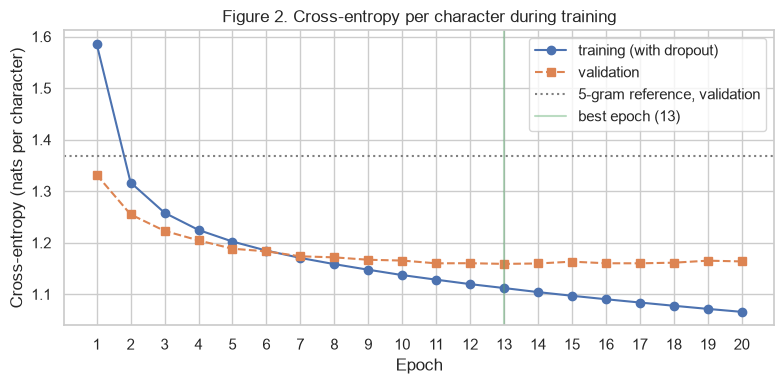

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["epoch"], history["train_loss"], marker="o", label="training (with dropout)")
ax.plot(history["epoch"], history["validation_loss"], marker="s", linestyle="--",
        label="validation")
ax.axhline(best_ngram["validation_loss"], color="grey", linestyle=":",
           label=f"{int(best_ngram['order'])}-gram reference, validation")
ax.axvline(best_epoch, color="C2", alpha=0.4, label=f"best epoch ({best_epoch})")
ax.set_title("Figure 2. Cross-entropy per character during training")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy (nats per character)")
ax.set_xticks(history["epoch"])
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** In Figure 2 the training loss falls from 1.5858 to 1.0658 over the 20 epochs. The validation loss falls from 1.3319 to 1.1654 in epoch 10 and then only moves between 1.1589 and 1.1651, with its lowest value in epoch 13. These differences are small, so with other random numbers another epoch could have been selected. After the first epoch the model is already below the validation loss of the 5-gram reference (1.3680). The training loss is measured with dropout, so in the first six epochs it lies above the validation loss. Later it is lower, and the gap grows to 0.0979 in epoch 20. The model fits the training names better and better while new names hardly improve any more, which suggests mild overfitting.

### Test loss

I evaluate the kept model once on the test split and compare it with the n-gram reference and with a model that gives every character the same probability.

In [24]:
test_loss = run_epoch(model, *data["test"])
ngram_test_loss = ngram.loss(test_names)
uniform_loss = math.log(config["vocabulary_size"] - 1)  # every token except padding
losses = pd.DataFrame({
    "model": ["uniform", f"{ngram.order}-gram reference", "Transformer"],
    "test_loss_nats": [uniform_loss, ngram_test_loss, test_loss],
})
losses["bits_per_character"] = losses["test_loss_nats"] / math.log(2)
losses["perplexity"] = np.exp(losses["test_loss_nats"])
losses.round(4)

,model,test_loss_nats,bits_per_character,perplexity
0,uniform,3.8918,5.6147,49.0000
1,5-gram reference,1.3819,1.9936,3.9823
2,Transformer,1.1634,1.6784,3.2007


**Interpretation:** On the test split the Transformer reaches 1.1634 nats per character, 1.6784 bits or a perplexity of 3.20. Roughly, it chooses between about three equally likely characters per step. The 5-gram reference reaches 1.3819 (perplexity 3.98), the uniform model over the 49 tokens other than padding 3.8918 (perplexity 49). The test loss is close to the best validation loss of 1.1589, so choosing the epoch on the validation names did not make the result look better than it is.

## Generation

To generate a name the model starts with the end marker, computes the logits for the next character, divides them by the temperature, turns them into probabilities, samples one character and appends it. It repeats this until it samples the end marker again or the name reaches 60 characters. A temperature below 1 makes the distribution sharper, so the model picks the likely characters more often. A temperature above 1 makes it flatter, so rare characters get more chances.

I generate 2,000 names at each of the temperatures 0.5, 0.8, 1.0 and 1.2, plus 2,000 names from the n-gram reference at temperature 1.0. I use seed 42 for the sampling at every temperature, so the generation is repeatable with the same weights. The saved names of the reference run are in `reference_run/generated_names.csv`.

In [25]:
@torch.no_grad()
def generate_names(model, count, temperature, seed):
    """Generate count names in parallel, return the names and whether each one was finished."""
    model.eval()
    generator = torch.Generator().manual_seed(seed)
    output_ids = torch.full((count, 1), END_ID, dtype=torch.long, device=device)
    finished = torch.zeros(count, dtype=torch.bool)
    # up to 60 characters and then the end marker, so CONTEXT_SIZE steps
    for step in range(CONTEXT_SIZE):
        logits = model(output_ids)[:, -1, :].float().cpu()
        logits[:, PAD_ID] = -torch.inf  # padding is never a valid next character
        probabilities = torch.softmax(logits / temperature, dim=-1)
        next_ids = torch.multinomial(probabilities, num_samples=1, generator=generator).squeeze(1)
        if step == CONTEXT_SIZE - 1:
            # after 60 characters only the end marker counts, a 61st character is dropped
            next_ids[next_ids != END_ID] = PAD_ID
        next_ids[finished] = PAD_ID  # finished names only get padding
        finished |= next_ids == END_ID
        output_ids = torch.cat([output_ids, next_ids.unsqueeze(1).to(device)], dim=1)
        if finished.all():
            break
    names_out = [tokenizer.decode(row) for row in output_ids[:, 1:].cpu().tolist()]
    return names_out, finished.tolist()

In [26]:
generated = []
for temperature in TEMPERATURES:
    start = time.time()
    batch, finished = generate_names(model, NAMES_PER_TEMPERATURE, temperature, seed=SEED)
    generated += [{"model": "Transformer", "temperature": temperature, "name": name,
                   "finished": done} for name, done in zip(batch, finished)]
    print(f"temperature {temperature}: {len(batch):,} names in {time.time() - start:.0f} s")
batch, finished = ngram.generate(NAMES_PER_TEMPERATURE, 1.0, seed=SEED, max_steps=CONTEXT_SIZE)
generated += [{"model": f"{ngram.order}-gram", "temperature": 1.0, "name": name, "finished": done}
              for name, done in zip(batch, finished)]
generated = pd.DataFrame(generated)
generated["setting"] = generated["model"] + ", T=" + generated["temperature"].astype(str)

temperature 0.5: 2,000 names in 38 s


temperature 0.8: 2,000 names in 47 s


temperature 1.0: 2,000 names in 49 s


temperature 1.2: 2,000 names in 57 s


In [27]:
# the first run of the reference run saves its names, every later run is compared with them
names_file = run_dir / "generated_names.csv"
columns = ["model", "temperature", "name", "finished"]
if run_dir == REFERENCE_DIR and names_file.exists():
    saved = pd.read_csv(names_file, keep_default_na=False)
    same = saved[columns].to_dict("records") == generated[columns].to_dict("records")
    print(f"identical to the saved names in {names_file}: {same}")
    if not same:
        # on other hardware single names can differ, the analysis then uses the saved names
        generated = saved[columns].copy()
        generated["setting"] = generated["model"] + ", T=" + generated["temperature"].astype(str)
else:
    generated[columns].to_csv(names_file, index=False)
    print(f"saved the generated names in {names_file}")

identical to the saved names in reference_run/generated_names.csv: True


In [28]:
# the first ten names of every setting, as they came out of the model
examples = generated.groupby("setting", sort=False).head(10).copy()
examples["position"] = examples.groupby("setting", sort=False).cumcount() + 1
table = examples.pivot(index="position", columns="setting", values="name")


In [29]:
display(table[[f"Transformer, T={t}" for t in TEMPERATURES]])

setting,"Transformer, T=0.5","Transformer, T=0.8","Transformer, T=1.0","Transformer, T=1.2"
position,,,,
1,ARCHITECTURE LIMITED,ARCHITECTURE LIMITED,ARCHITECTURE LIMITED,AAAZ SHIM LTD
2,BELLE CARE LTD,BELLE CLARK HOLDINGS LTD,BELLE CLARK HOLDINGS LTD,BEFER CLAIM SERVICES LTD
3,FOOD STREET LIMITED,FOUNTHILL CREATIVE LIMITED,FAAVOUR TECHNOLOGY LIMITED,FGANOS LTD
4,CALNAN HOUSE LTD,CAUNTRY CAR WASH LIMITED,CAUNTRIDGE CONSORTIUM WOOD HOUSE LIMITED,CAUNTRIDGE CONSORTIUM WOOD HIRE LTD
5,MEDIA SUPPLY LTD,MEDIA RETAILING LTD,MEDIAPROPERTIES LTD,MEDIAPRIGHT LIMITED
6,PINNACLE STREET NORTH WEST LTD,PIZZA FOOD BUCKLE LIMITED,PIZZA FOOD BUCKLE LIMITED,XIIMAT LTD
7,GREEN NEWS ACADEMY LIMITED,GREEN NEWCO LTD,GREEN NEWCO LTD,GROWS NEWCO LTD
8,GREEN SALON LIMITED,GRID CONSULTANCY LIMITED,GRID-CONSULTANTS (DESIGN & SPITALISH 25) LIMITED,GRID-COACHING LIMITED
9,MIRDS CARPENTRY LTD,MIRDS RICHARD LETTINGS LIMITED,MIRDSWAY LTD,MIRDSWAY LTD


In [30]:
display(table[[f"{ngram.order}-gram, T=1.0"]])

setting,"5-gram, T=1.0"
position,
1,SIRN'YOP)@6WIR9/E&RHO5YUP-@!+KNY36A-)A/J9RL3RQ62K)-
2,SPLINE CONSULTING HOUSE HOMES LIMITED
3,BOOKING CONSTRUCTIONAL LIMITED
4,OAK HEALTHCARE SERVICES LIMITED
5,"MARINE COMMODITIONINO )9ZUNUUC3OJ6'N0W/)R+,GT-3PYB+"
6,DATA MC3QMN))W72AJX2W EI()8YGWQ@P
7,BROCKEY INVESTMENT COMPANY LIMITED
8,"PHGASS!,/0E8!6C'R!W'SVYQPIP)DCT@6I1)A8/6546K2XVA4DSIQDI2N-LT"
9,"MARCU2XQGPPX0F'H,EF@COQBGW(('J8OJ4VO153++W96MEWPA6ZMX(SI(FK"


**Interpretation:** These names are not chosen by me. All Transformer settings use the same seed, so they draw the same random numbers, and the names in one row often start alike. MIRDS CARPENTRY LTD at 0.5 becomes MIRDS RICHARD LETTINGS LIMITED at 0.8. At 0.5 the names are mostly short and generic, like MEDIA SUPPLY LTD or FOOD STREET LIMITED. At the higher temperatures more unknown words appear, like FAAVOUR TECHNOLOGY LIMITED, FGANOS LTD or XIIMAT LTD. Six of the ten 5-gram names break into random-looking characters, like SIRN'YOP)@6WIR9/... After a context that never appeared in training, every character is equally likely, so one random character often leads to the next unknown context. The Transformer names are much more regular, although I did not test how much of this comes from attention alone.

## Evaluation

No single number says whether a generated name is good, so I check several things, which I fixed before I looked at the names. A name is finished if the model wrote the end marker within 60 characters, and it has a valid ending if its last word is LTD, LTD. or LIMITED, like every training name. The distinct share is the number of different names divided by the 2,000 names of a setting. A name is an exact training copy if it is the same as a training name, character for character. Then I compare the "same as" key of every name with the keys of the training names and with the keys of the 5.7 million live companies in the snapshot, the training names included. As explained in the dataset section, a register match is a possible collision and not a legal test. I run the same checks on the real test names, because they show what to expect from real names that the model never saw.

In [31]:
train_set = set(train_names)
train_keys = {same_as_key(name) for name in train_names}


def in_register(key_list):
    """Return for every key whether its hash is one of the sorted register hashes."""
    hashes = np.array([key_hash(key) for key in key_list], dtype=np.uint64)
    positions = np.minimum(np.searchsorted(register_keys, hashes), len(register_keys) - 1)
    return register_keys[positions] == hashes


def add_checks(frame):
    """Add the quality checks and the key matches as columns to a table of names."""
    frame["valid_ending"] = frame["name"].str.split().str[-1].isin(NAME_ENDINGS)
    frame["length"] = frame["name"].str.len()
    frame["key"] = frame["name"].map(same_as_key)
    frame["exact_training_copy"] = frame["name"].isin(train_set)
    frame["training_key_match"] = frame["key"].isin(train_keys)
    frame["register_key_match"] = in_register(frame["key"])
    frame["register_not_training"] = frame["register_key_match"] & ~frame["training_key_match"]
    frame["duplicate"] = frame.duplicated(["setting", "name"])
    return frame

In [32]:
generated = add_checks(generated)
# the real test names get the same checks, they show what to expect from names the model never saw
real_test = pd.DataFrame({"setting": "real test names", "name": test_names, "finished": True})
real_test = add_checks(real_test)

In [33]:
summary = pd.concat([generated, real_test]).groupby("setting", sort=False).agg(
    names=("name", "size"),
    finished=("finished", "mean"),
    valid_ending=("valid_ending", "mean"),
    distinct_share=("duplicate", lambda d: 1 - d.mean()),
    exact_training_copy=("exact_training_copy", "mean"),
    training_key_match=("training_key_match", "mean"),
    register_key_match=("register_key_match", "mean"),
    register_not_training=("register_not_training", "mean"),
    mean_length=("length", "mean"),
)
summary.round(4)

,names,finished,valid_ending,distinct_share,exact_training_copy,training_key_match,register_key_match,register_not_training,mean_length
setting,,,,,,,,,
"Transformer, T=0.5",2000,1.0000,1.000,0.9695,0.0040,0.0115,0.4935,0.4820,21.2935
"Transformer, T=0.8",2000,1.0000,1.000,0.9995,0.0040,0.0085,0.2395,0.2310,21.7115
"Transformer, T=1.0",2000,1.0000,1.000,1.0000,0.0010,0.0045,0.1385,0.1340,22.1195
"Transformer, T=1.2",2000,0.9995,0.997,1.0000,0.0000,0.0015,0.0605,0.0590,23.2580
"5-gram, T=1.0",2000,0.7780,0.326,0.9955,0.0005,0.0070,0.1440,0.1370,31.9615
real test names,10023,1.0000,1.000,1.0000,0.0000,0.0001,1.0000,0.9999,22.9535


**Interpretation:** The Transformer finishes all names but one, and 99.70% to 100% of its names end with LTD, LTD. or LIMITED. At 0.5 only 96.95% of the 2,000 names are different, at the other temperatures 99.95% or 100%. Exact copies of training names are rare, 8 at 0.5, 8 at 0.8, 2 at 1.0 and none at 1.2, so 18 of all 8,000. The key of 0.15% to 1.15% of the names matches a training name.

The register check shows a much bigger problem. At 0.5 the key of 49.35% of the names matches a company in the snapshot, at 0.8 23.95%, at 1.0 13.85% and at 1.2 still 6.05%. Almost none of these names has the key of a training name (`register_not_training` is at most 1.15 percentage points lower). So copied training names explain only a small part, and most matches seem to be common names that real companies already use. The checks cannot show whether the model learned parts of names by heart. All 10,023 real test names are found in the register, which shows that the lookup works.

The 5-gram reference finishes only 77.80% of its names within 60 characters, and only 32.60% end correctly. Its mean length of 32.0 characters comes from these broken names that run to the limit.

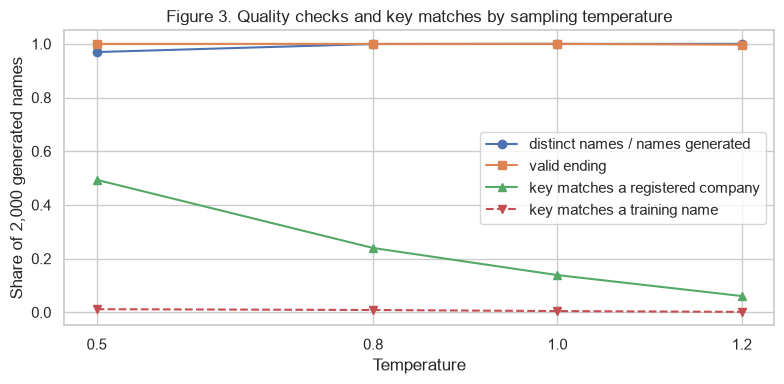

In [34]:
transformer = generated[generated["model"] == "Transformer"]
checks = ["valid_ending", "training_key_match", "register_key_match"]
shares = transformer.groupby("temperature")[checks].mean()
distinct = transformer.groupby("temperature")["duplicate"].mean().rsub(1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(shares.index, distinct, marker="o", label="distinct names / names generated")
ax.plot(shares.index, shares["valid_ending"], marker="s", label="valid ending")
ax.plot(shares.index, shares["register_key_match"], marker="^",
        label="key matches a registered company")
ax.plot(shares.index, shares["training_key_match"], marker="v", linestyle="--",
        label="key matches a training name")
ax.set_title("Figure 3. Quality checks and key matches by sampling temperature")
ax.set_xlabel("Temperature")
ax.set_ylabel(f"Share of {NAMES_PER_TEMPERATURE:,} generated names")
ax.set_xticks(TEMPERATURES)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** In Figure 3 the distinct share and the valid endings stay close to 1 at every temperature. The register matches fall fast when the temperature rises, and the training-key matches stay close to zero. For my use case, test names that should not match a real company, a higher temperature is better on this check. But at a higher temperature more names also contain words that are not in the training names, as the next checks show.

### How close are the new names to the training names?

A name can also be almost a copy, for example with one word changed. For every name I look for the most similar training name. I measure this with the cosine similarity of TF-IDF weighted character 2- to 4-grams, so the check only looks at shared groups of characters. A high or low value alone does not show whether a name is a copy or reads like a real name. For comparison I do the same for 2,000 real validation names. The model never saw them in training, so a model that writes names like real ones should give about the same values. I use the validation names and not the test names, so the test names stay out of this comparison.

In [35]:
vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True)
train_vectors = vectorizer.fit_transform(train_names)


def closest_training_name(query_names):
    """Return the most similar training name and its cosine similarity for every query name."""
    best_names, best_scores = [], []
    for start in range(0, len(query_names), 500):
        similarity = vectorizer.transform(query_names[start:start + 500]) @ train_vectors.T
        best_index = np.asarray(similarity.argmax(axis=1)).ravel()
        best_scores += similarity.max(axis=1).toarray().ravel().tolist()
        best_names += [train_names[i] for i in best_index]
    return best_names, best_scores

In [36]:
# the real validation names are the comparison, the test names stay out
rng = np.random.default_rng(SEED)
validation_sample = list(rng.choice(validation_names, size=NAMES_PER_TEMPERATURE, replace=False))
groups = {"real validation names": validation_sample}
for setting in generated["setting"].unique():
    groups[setting] = generated.loc[generated["setting"] == setting, "name"].tolist()

closest = []
for label, query_names in groups.items():
    neighbour, score = closest_training_name(query_names)
    closest += [{"group": label, "name": n, "closest_training_name": c, "similarity": s}
                for n, c, s in zip(query_names, neighbour, score)]
closest = pd.DataFrame(closest)
closest.groupby("group", sort=False)["similarity"].describe(percentiles=[0.5, 0.9]).round(3)

,count,mean,std,min,50%,90%,max
group,,,,,,,
real validation names,2000.0,0.579,0.114,0.186,0.584,0.726,0.931
"Transformer, T=0.5",2000.0,0.693,0.106,0.345,0.685,0.834,1.000
"Transformer, T=0.8",2000.0,0.623,0.120,0.265,0.623,0.778,1.000
"Transformer, T=1.0",2000.0,0.572,0.127,0.218,0.573,0.738,1.000
"Transformer, T=1.2",2000.0,0.518,0.123,0.218,0.512,0.684,0.910
"5-gram, T=1.0",2000.0,0.390,0.201,0.097,0.335,0.694,1.000


In [37]:
# a similarity of 1 means the same character patterns, not always the same name
top = closest[closest["similarity"] >= 0.999].copy()
top["exact_copy"] = top["name"] == top["closest_training_name"]
pairs = top.groupby("group", sort=False)["exact_copy"].agg(pairs="size", exact_copies="sum")
print(pairs.to_string())
top[~top["exact_copy"]][["group", "name", "closest_training_name", "similarity"]].head(10)

                    pairs  exact_copies
group                                  
Transformer, T=0.5      8             8
Transformer, T=0.8      8             8
Transformer, T=1.0      3             2
5-gram, T=1.0           1             1


,group,name,closest_training_name,similarity
6610,"Transformer, T=1.0",HOMES ATTA LIMITED,ATTA HOMES LIMITED,1.0


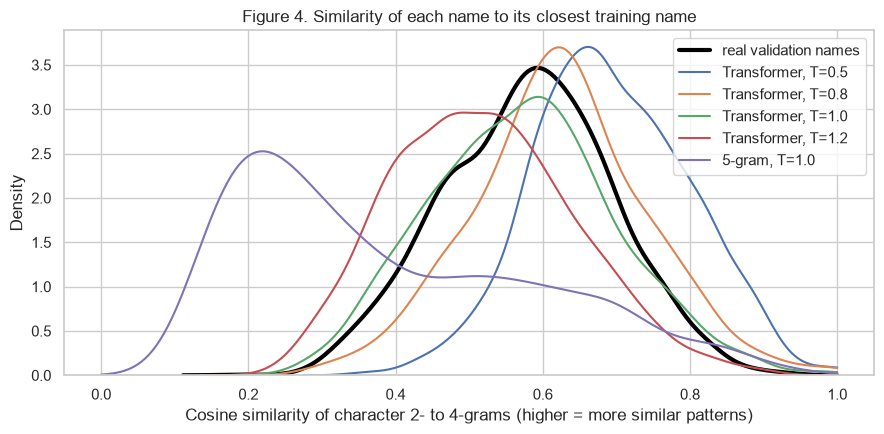

In [38]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.kdeplot(closest.loc[closest["group"] == "real validation names", "similarity"], ax=ax,
            label="real validation names", clip=(0, 1), linewidth=3, color="black")
for label in [f"Transformer, T={t}" for t in TEMPERATURES] + [f"{ngram.order}-gram, T=1.0"]:
    sns.kdeplot(closest.loc[closest["group"] == label, "similarity"], ax=ax, label=label,
                clip=(0, 1), linewidth=1.5)
ax.set_title("Figure 4. Similarity of each name to its closest training name")
ax.set_xlabel("Cosine similarity of character 2- to 4-grams (higher = more similar patterns)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** A similarity of 1 means the same character groups, but not always the same name, because the order of the words does not count. In this run 20 pairs reach at least 0.999. 19 are exact copies, 18 from the Transformer and 1 from the 5-gram model. The last one is HOMES ATTA LIMITED against the training name ATTA HOMES LIMITED. The real validation names have a median similarity of 0.584 to their closest training name. The Transformer comes closest to this at temperature 1.0 (median 0.573), and in Figure 4 its curve lies just left of the black curve of the real names. At 0.5 the median rises to 0.685, so these names share more character groups with training names. At 0.8 the median is 0.623 and at 1.2 0.512. The 5-gram names have a median of only 0.335, because many of them are broken and share few character groups with real names.

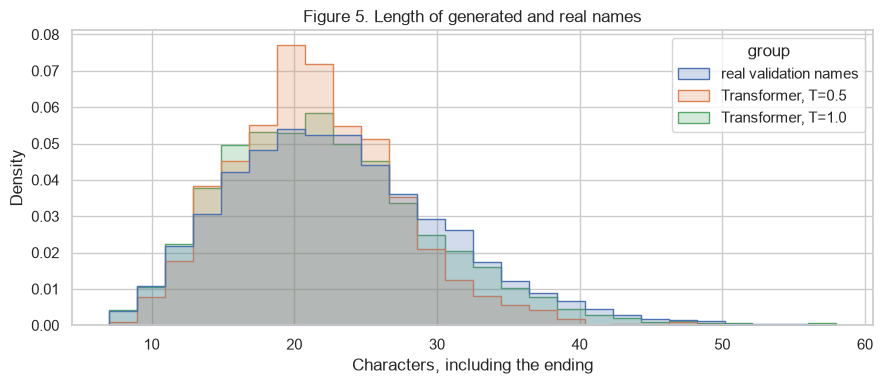

                          mean  over_30
group                                  
Transformer, T=0.5     21.2935   0.0665
Transformer, T=1.0     22.1195   0.1325
real validation names  22.9504   0.1650


In [39]:
fig, ax = plt.subplots(figsize=(9, 4))
lengths = pd.concat([
    pd.DataFrame({"group": "real validation names", "length": [len(n) for n in validation_names]}),
    transformer.loc[transformer["temperature"].isin([0.5, 1.0]), ["temperature", "length"]]
    .assign(group=lambda d: "Transformer, T=" + d["temperature"].astype(str))[["group", "length"]],
])
sns.histplot(data=lengths, x="length", hue="group", stat="density", common_norm=False,
             element="step", binwidth=2, ax=ax)
ax.set_title("Figure 5. Length of generated and real names")
ax.set_xlabel("Characters, including the ending")
ax.set_ylabel("Density")
plt.tight_layout()
plt.show()
length_stats = lengths.groupby("group")["length"].agg(
    mean="mean", over_30=lambda l: (l > 30).mean())
print(length_stats.round(4).to_string())

**Interpretation:** In Figure 5 the lengths at temperature 1.0 are close to those of the real validation names, with a mean of 22.12 characters against 22.95. At 0.5 the names are shorter (mean 21.29), and only 6.65% have more than 30 characters, against 13.25% at 1.0 and 16.50% of the real names.

In [40]:
def word_shares(name_list):
    """Return the share of names that contain each word, without the ending."""
    counts = Counter(word for name in name_list for word in set(name_words(name)))
    return pd.Series(counts) / len(name_list)


word_table = pd.DataFrame({"training": word_shares(train_names)})
for setting in ["Transformer, T=0.5", "Transformer, T=1.0"]:
    setting_names = generated.loc[generated["setting"] == setting, "name"].tolist()
    word_table[setting] = word_shares(setting_names)
word_table = word_table.fillna(0).sort_values("training", ascending=False)
word_table.head(12).round(4)

,training,"Transformer, T=0.5","Transformer, T=1.0"
SERVICES,0.0480,0.0390,0.0340
&,0.0450,0.0185,0.0350
PROPERTY,0.0264,0.0860,0.0260
AND,0.0242,0.0310,0.0210
GROUP,0.0234,0.0135,0.0165
SOLUTIONS,0.0226,0.0280,0.0135
MANAGEMENT,0.0225,0.0370,0.0200
THE,0.0223,0.0680,0.0230
PROPERTIES,0.0218,0.0360,0.0190
HOLDINGS,0.0214,0.0220,0.0280


**Interpretation:** At the low temperature the model uses some words much more often than the training names do. At 0.5 PROPERTY is in 8.60% of the names instead of 2.64% in the training data, THE in 6.80% instead of 2.23% and CONSULTING in 4.30% instead of 1.57%. Other words become rarer, like `&`, GROUP and UK (UK 0.20% instead of 1.79%). So at 0.5 the model repeats a few common patterns and uses others less. At 1.0 the twelve words stay within 1.4 percentage points of the training shares, the largest gap is SERVICES with 3.40% against 4.80%.

In [41]:
# share of names with at least one word that never appears in the training names
training_words = set(word_counts)


def has_new_word(name):
    """Return True if a word of the name (without the ending) is not in the training names."""
    return any(word not in training_words for word in name_words(name))


new_word_share = generated.groupby("setting", sort=False)["name"].apply(
    lambda s: s.map(has_new_word).mean())
new_word_share["real validation names"] = np.mean([has_new_word(n) for n in validation_names])
print("Share of names with at least one word that is not in the training names:")
print(new_word_share.round(4).to_string())

Share of names with at least one word that is not in the training names:
setting
Transformer, T=0.5       0.1590
Transformer, T=0.8       0.4275
Transformer, T=1.0       0.6485
Transformer, T=1.2       0.7985
5-gram, T=1.0            0.8385
real validation names    0.5110


In [42]:
# collisions with the register by number of words, for the Transformer at T=0.8
at_08 = generated[generated["setting"] == "Transformer, T=0.8"].copy()
at_08["words"] = at_08["name"].str.split().str.len().clip(upper=5)
print("Transformer, T=0.8, key matches a registered company by number of words (5 = five or more):")
print(at_08.groupby("words")["register_key_match"].agg(["size", "mean"]).round(4).to_string())

Transformer, T=0.8, key matches a registered company by number of words (5 = five or more):
       size    mean
words              
2       291  0.4021
3      1082  0.2736
4       464  0.1142
5       163  0.0798


**Interpretation:** This check counts the names with at least one word (anything between two spaces) that is not in the training names. It shows how new the words are, not how good the names are, because such a word can be a real name, a number, a code, a misspelling or an invented word. For the real validation names the share is 51.10%. The Transformer has 15.90% at 0.5, 42.75% at 0.8, 64.85% at 1.0 and 79.85% at 1.2, so the real names lie between 0.8 and 1.0. Short names match the register most often. At 0.8 the key of 40.21% of the 291 names with two words matches, but only 11.42% of the names with four words and 7.98% of the longer ones.

### Choice of temperature

For my use case I want test names that look like real company names. I choose the temperature with a simple rule on the validation names. I wrote this rule only after an earlier version of this notebook had compared the temperatures on the test names, so the rule was not fixed in advance, and the comparison with the test names further below cannot confirm it. The rule takes the temperature whose similarity values (Figure 4) are closest to those of the 2,000 real validation names. I measure this with the Kolmogorov-Smirnov distance, the largest gap between the two cumulative distributions. 0 means the same distribution and 1 means no overlap. The rule does not look at copies, at register matches or at whether a name reads well, and it uses all generated names, also the ones that fail a check. The table also shows the length, the share of names with a new word and the register matches.

In [43]:
def ks_distance(sample_a, sample_b):
    """Return the Kolmogorov-Smirnov distance of two samples, from 0 (same) to 1 (no overlap)."""
    sample_a, sample_b = np.sort(np.asarray(sample_a)), np.sort(np.asarray(sample_b))
    values = np.concatenate([sample_a, sample_b])
    gaps = (np.searchsorted(sample_a, values, side="right") / len(sample_a)
            - np.searchsorted(sample_b, values, side="right") / len(sample_b))
    return float(np.abs(gaps).max())

In [44]:
validation_similarity = closest.loc[closest["group"] == "real validation names", "similarity"]
validation_lengths = [len(name) for name in validation_names]
rows = []
for temperature in TEMPERATURES:
    setting = f"Transformer, T={temperature}"
    setting_rows = generated[generated["setting"] == setting]
    rows.append({
        "temperature": temperature,
        "similarity_distance": ks_distance(closest.loc[closest["group"] == setting, "similarity"],
                                           validation_similarity),
        "length_distance": ks_distance(setting_rows["length"], validation_lengths),
        "new_word_share": new_word_share[setting],
        "register_key_match": setting_rows["register_key_match"].mean(),
    })
choice = pd.DataFrame(rows).set_index("temperature")
chosen_temperature = float(choice["similarity_distance"].idxmin())
chosen = f"Transformer, T={chosen_temperature}"
print(f"Chosen temperature: {chosen_temperature}")
choice.round(4)

Chosen temperature: 1.0


,similarity_distance,length_distance,new_word_share,register_key_match
temperature,,,,
0.5,0.3800,0.1211,0.1590,0.4935
0.8,0.1525,0.0816,0.4275,0.2395
1.0,0.0535,0.0531,0.6485,0.1385
1.2,0.2330,0.0255,0.7985,0.0605


**Interpretation:** The rule picks temperature 1.0. Its similarity distance to the real validation names is 0.0535, clearly lower than at 0.8 (0.1525), 1.2 (0.2330) and 0.5 (0.3800), which matches Figure 4. Its length distance of 0.0531 is the second lowest, only 1.2 is lower (0.0255).

Now I compare the chosen temperature with the test names. As explained above, this cannot confirm the choice, it only shows whether the test names give similar values.

In [45]:
# the test names are compared with the chosen temperature only
rng = np.random.default_rng(SEED)
test_sample = list(rng.choice(test_names, size=NAMES_PER_TEMPERATURE, replace=False))
_, test_similarity = closest_training_name(test_sample)
test_lengths = [len(name) for name in test_names]
chosen_rows = generated[generated["setting"] == chosen]
chosen_similarity = closest.loc[closest["group"] == chosen, "similarity"]
print(f"Similarity distance of {chosen} to the validation names: "
      f"{ks_distance(chosen_similarity, validation_similarity):.4f}, to the test names: "
      f"{ks_distance(chosen_similarity, test_similarity):.4f}")
print(f"Length distance to the validation names: "
      f"{ks_distance(chosen_rows['length'], validation_lengths):.4f}, "
      f"to the test names: {ks_distance(chosen_rows['length'], test_lengths):.4f}")
pd.DataFrame({
    chosen: [chosen_similarity.median(), chosen_rows["length"].mean(), new_word_share[chosen]],
    "real validation names": [validation_similarity.median(), np.mean(validation_lengths),
                              new_word_share["real validation names"]],
    "real test names": [np.median(test_similarity), np.mean(test_lengths),
                        np.mean([has_new_word(name) for name in test_names])],
}, index=["median similarity", "mean length", "share with a new word"]).round(4)

Similarity distance of Transformer, T=1.0 to the validation names: 0.0535, to the test names: 0.0690
Length distance to the validation names: 0.0531, to the test names: 0.0485


,"Transformer, T=1.0",real validation names,real test names
median similarity,0.5730,0.5842,0.5862
mean length,22.1195,22.9504,22.9535
share with a new word,0.6485,0.5110,0.5029


**Interpretation:** On the test names the chosen temperature gives a similarity distance of 0.0690, a bit more than the 0.0535 on the validation names, and a length distance of 0.0485, a bit less than the 0.0531. The real test and validation names give almost the same values on all three measures, for example a median similarity of 0.5862 and 0.5842. I compared only four temperatures, so 1.0 is the best of these four under my rule, not the best temperature overall.